<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/K_Means_Optimization_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Assignment 1: K-Means Optimization for Online Retail Customer Segmentation
Objective: Perform comprehensive customer segmentation for an online retail company using K-Means clustering with optimal K determination and detailed cluster profiling.

Dataset: Assignment-Dataset/assignment1_customer_segmentation.csv (250 customers)

Features: Recency_Days, Frequency, Monetary_Value, Avg_Session_Duration_Min, Pages_Visited, Items_in_Cart, Customer_Tenure_Months, Discount_Usage_Rate

Context: An e-commerce company wants to understand their customer base by grouping them into meaningful segments based on shopping behavior. These segments will inform targeted marketing campaigns.

Instructions:

Data Loading & Exploration

Load the dataset and display basic info (.head(), .info(), .describe())
Check for missing values
Generate summary statistics for all numerical features
Exploratory Data Analysis (EDA)

Create histograms for each feature to understand distributions
Generate a correlation heatmap to identify relationships between features
Create box plots for key features (Monetary_Value, Frequency, Recency_Days)
Feature Scaling

Apply StandardScaler to all features before clustering
Explain why feature scaling is critical for K-Means
Elbow Method Analysis

Test K values from 1 to 15
Plot K vs. WCSS
Identify the optimal K value and justify your choice
Build K-Means Model

Fit K-Means with the optimal K
Add cluster labels to the original dataset
Cluster Profiling & Interpretation

Calculate the mean values of each feature per cluster
Create a profile table showing cluster characteristics
Assign a descriptive business name to each cluster (e.g., "High-Value Loyalists", "At-Risk Customers", etc.)
Create visualizations to compare clusters (bar charts of average feature values per cluster)
Discussion

What marketing strategies would you recommend for each customer segment?
How does the Elbow Method help avoid overfitting or underfitting in clustering?
What are the limitations of K-Means for this type of analysis?
Deliverables:

Complete EDA with visualizations
Elbow Method plot with justified K selection
Cluster profile table with business segment names
Cluster comparison visualizations
Written marketing strategy recommendations for each segment

In [ ]:
#importing the needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#importing the datasets
data = pd.read_csv('/content/drive/MyDrive/assignment1_customer_segmentation.csv')
data.head(20)

,Customer_ID,Recency_Days,Frequency,Monetary_Value,Avg_Session_Duration_Min,Pages_Visited,Items_in_Cart,Customer_Tenure_Months,Discount_Usage_Rate
0,CUST_0143,33,4,1377.77,31.8,25,6,13,0.48
1,CUST_0007,11,15,166.52,9.3,16,4,9,0.89
2,CUST_0098,60,1,460.11,3.0,3,1,25,0.18
3,CUST_0061,4,39,1029.30,27.3,39,14,49,0.30
4,CUST_0113,92,2,190.78,3.5,6,2,22,0.01
5,CUST_0182,28,11,41.61,27.0,50,0,13,0.04
6,CUST_0198,13,8,37.16,27.1,54,1,9,0.07
7,CUST_0185,6,18,85.25,39.0,58,0,9,0.09
8,CUST_0010,4,22,80.42,12.7,18,4,11,0.53
9,CUST_0105,80,1,117.55,4.8,3,1,25,0.06


In [ ]:
#Checking the data information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               250 non-null    object 
 1   Recency_Days              250 non-null    int64  
 2   Frequency                 250 non-null    int64  
 3   Monetary_Value            250 non-null    float64
 4   Avg_Session_Duration_Min  250 non-null    float64
 5   Pages_Visited             250 non-null    int64  
 6   Items_in_Cart             250 non-null    int64  
 7   Customer_Tenure_Months    250 non-null    int64  
 8   Discount_Usage_Rate       250 non-null    float64
dtypes: float64(3), int64(5), object(1)
memory usage: 17.7+ KB


In [ ]:
#data statistical description for the numerical values
data.describe()

,Recency_Days,Frequency,Monetary_Value,Avg_Session_Duration_Min,Pages_Visited,Items_in_Cart,Customer_Tenure_Months,Discount_Usage_Rate
count,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000
mean,26.216000,12.560000,510.916520,20.793600,23.528000,3.416000,16.536000,0.310840
std,29.283158,11.396047,546.168096,12.601417,14.752075,3.209384,14.963433,0.239161
min,1.000000,1.000000,22.410000,2.300000,2.000000,0.000000,0.000000,0.000000
25%,6.000000,3.000000,95.002500,10.200000,11.250000,1.000000,5.000000,0.100000
50%,14.000000,8.000000,237.170000,18.450000,20.000000,2.000000,12.000000,0.240000
75%,33.750000,20.750000,935.512500,30.375000,33.750000,5.000000,24.000000,0.510000
max,117.000000,39.000000,1988.440000,49.600000,59.000000,14.000000,59.000000,0.900000


In [ ]:
#checking for the missing values
data.isna().sum()

,0
Customer_ID,0
Recency_Days,0
Frequency,0
Monetary_Value,0
Avg_Session_Duration_Min,0
Pages_Visited,0
Items_in_Cart,0
Customer_Tenure_Months,0
Discount_Usage_Rate,0


EDA PROCESS

In [ ]:
#selecting the numerical features
num_features =data.drop('Customer_ID', axis=1)
num_features.head()

,Recency_Days,Frequency,Monetary_Value,Avg_Session_Duration_Min,Pages_Visited,Items_in_Cart,Customer_Tenure_Months,Discount_Usage_Rate
0,33,4,1377.77,31.8,25,6,13,0.48
1,11,15,166.52,9.3,16,4,9,0.89
2,60,1,460.11,3.0,3,1,25,0.18
3,4,39,1029.30,27.3,39,14,49,0.30
4,92,2,190.78,3.5,6,2,22,0.01


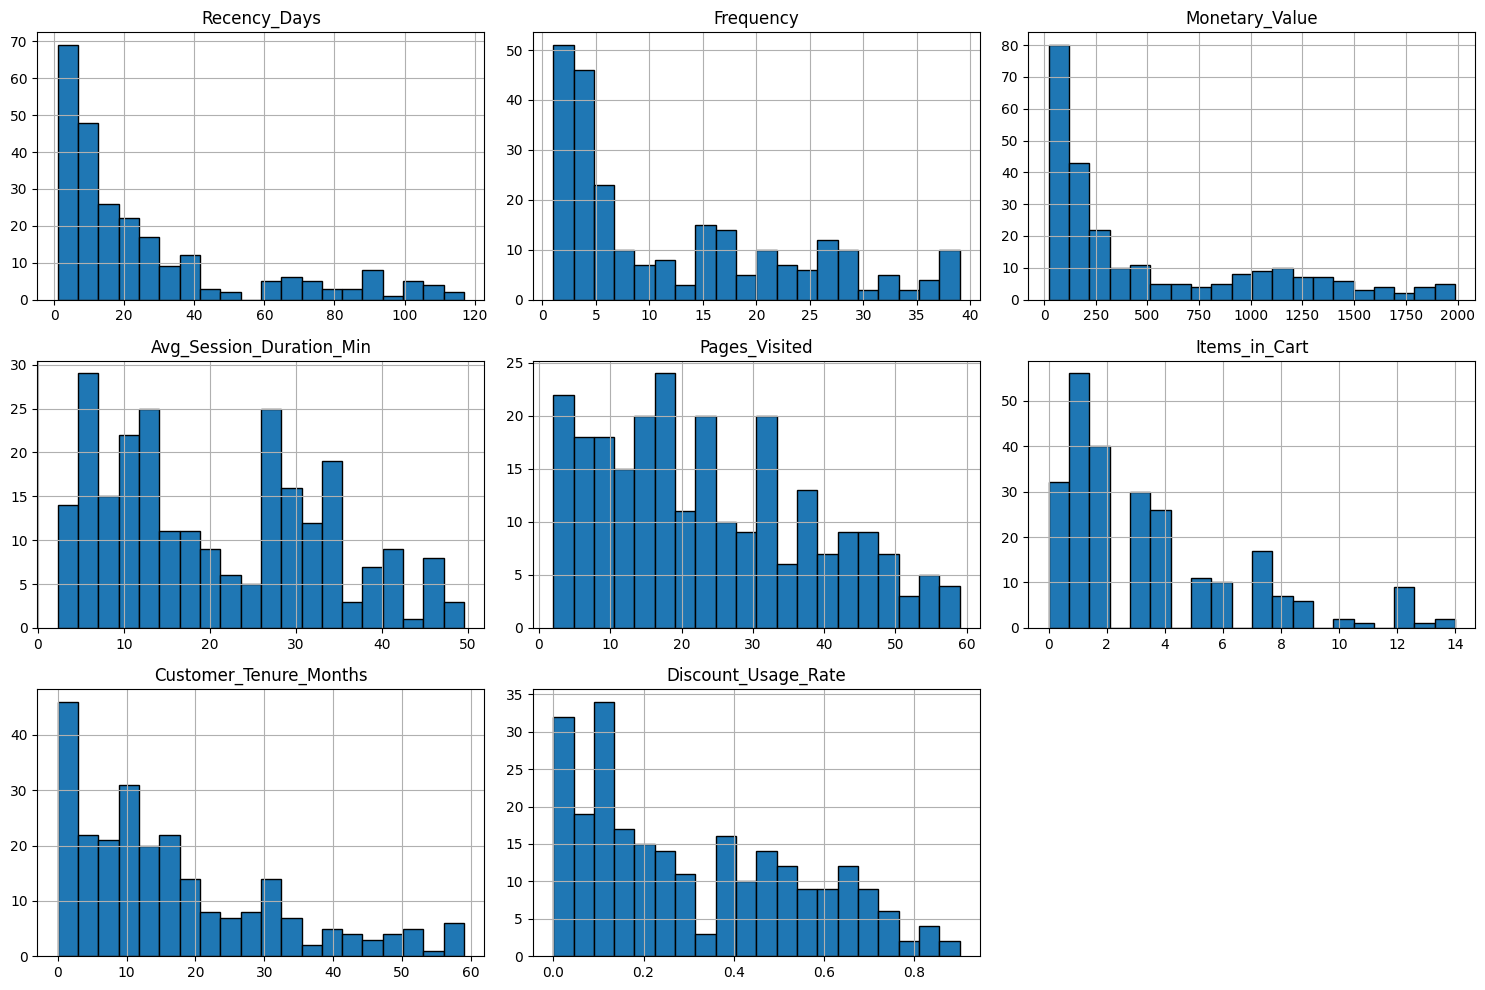

In [ ]:
# Plotting histograms for all numerical features
num_features.hist(bins=20, figsize=(15,10), edgecolor='black')
plt.tight_layout()
plt.show()

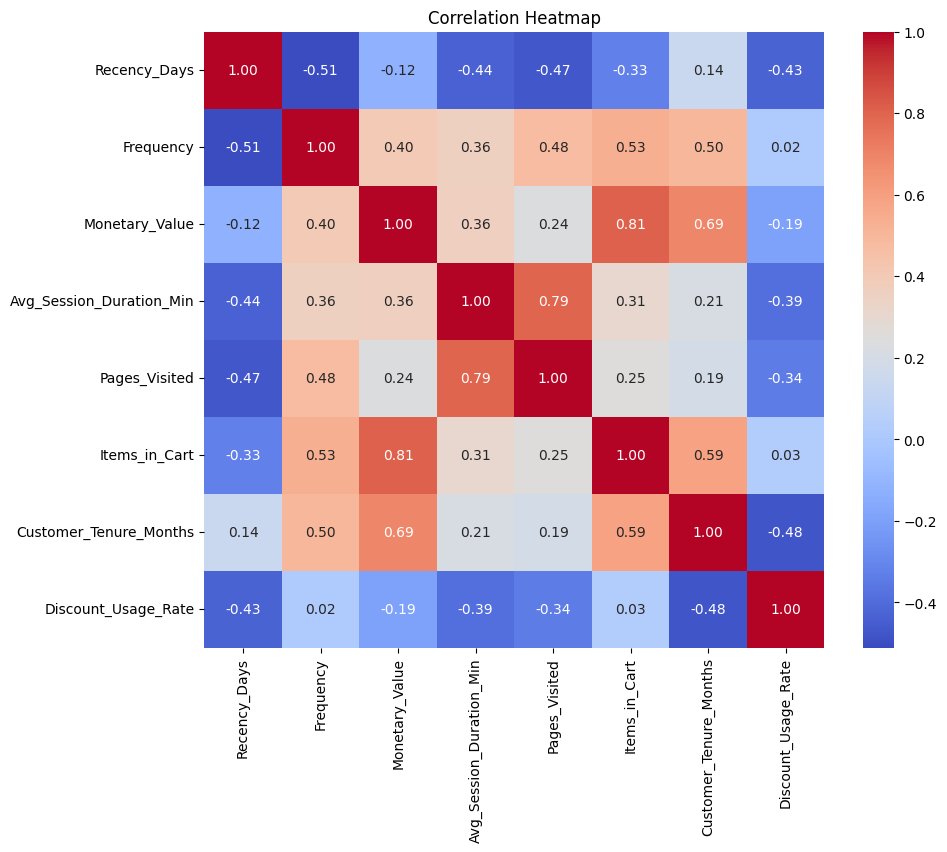

In [ ]:
# Computing correlation matrix
corr_matrix = num_features.corr()

# Plotting heatmap
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

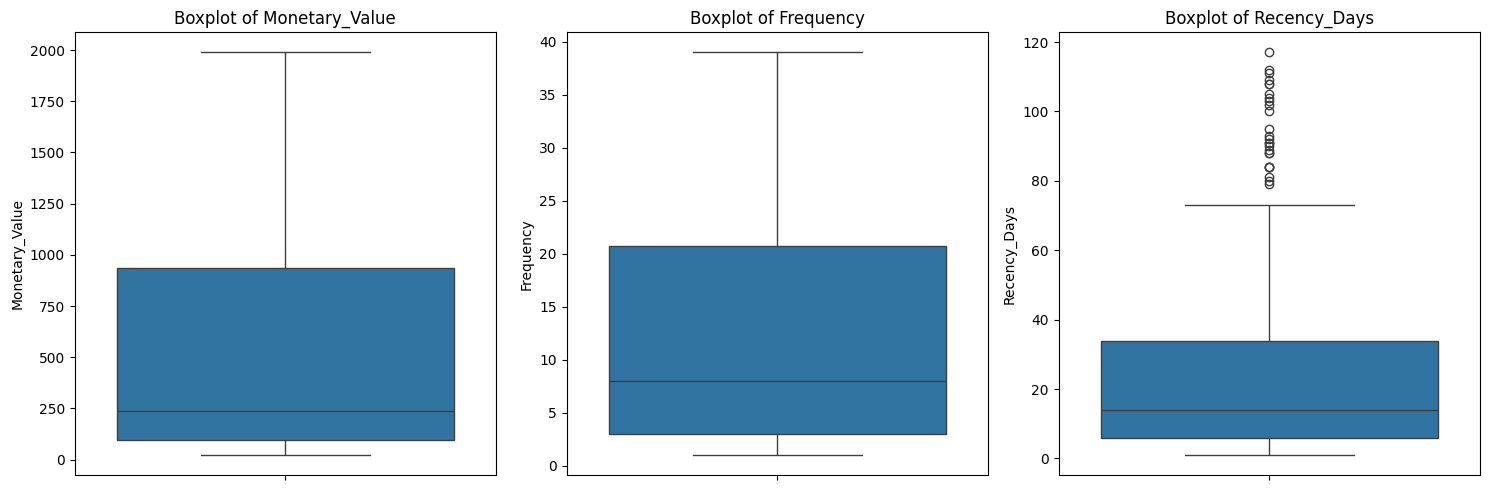

In [ ]:
#creating boxplots for the key features
key_features = ['Monetary_Value', 'Frequency', 'Recency_Days']

plt.figure(figsize=(15,5))
for i, feature in enumerate(key_features):
    plt.subplot(1, 3, i+1)
    sns.boxplot(y=data[feature])
    plt.title(f'Boxplot of {feature}')
plt.tight_layout()
plt.show()

In [ ]:
#feature scaling
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Using StandardScaler
scaler = StandardScaler()
scaled_features = scaler.fit_transform(data[num_features.columns])

# Create a new DataFrame with scaled values
scaled_data = pd.DataFrame(scaled_features, columns=num_features.columns)
scaled_data.head()

,Recency_Days,Frequency,Monetary_Value,Avg_Session_Duration_Min,Pages_Visited,Items_in_Cart,Customer_Tenure_Months,Discount_Usage_Rate
0,0.232134,-0.752644,1.590339,0.875178,0.099983,0.806754,-0.236783,0.708724
1,-0.520658,0.214539,-0.631834,-0.913918,-0.511325,0.182331,-0.504638,2.426488
2,1.156015,-1.016422,-0.093210,-1.414864,-1.394325,-0.754303,0.566780,-0.548176
3,-0.760183,2.324757,0.951032,0.517359,1.050906,3.304445,2.173908,-0.045416
4,2.250985,-0.928496,-0.587326,-1.375107,-1.190555,-0.442091,0.365889,-1.260420


 StandardScaler standardizes numerical features by subtracting the mean and dividing by the standard deviation. This gives each feature a mean of 0 and a standard deviation of 1. Scaling is important for K-Means because it ensures all features contribute equally to distance calculations, preventing features with larger values from dominating the clustering.

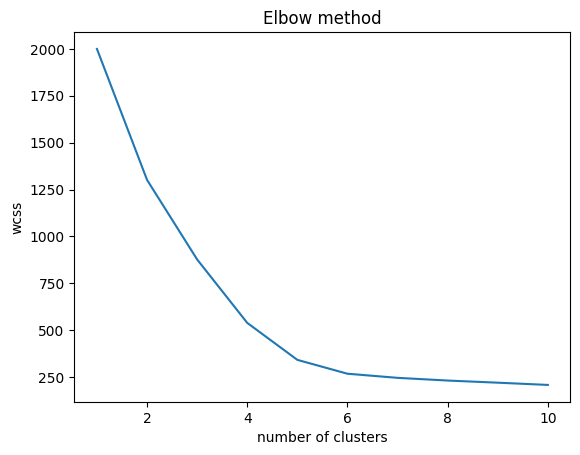

In [ ]:
#Test K values from 1 to 15 Plot K vs. WCSS Identify the optimal K value and justify your choice Build K-Means Model
from sklearn.cluster import KMeans
wcss = []
#creating the for loop using the range of (1, 11) as it is the possible values of k this means we are testing 1 to 10 as the value of k
for i in range(1,11):
  kmeans = KMeans(n_clusters=i, init='k-means++', n_init=10, max_iter=300, random_state=0)
  kmeans.fit(scaled_data)
  wcss.append(kmeans.inertia_)
plt.plot(range(1,11), wcss)
plt.title('Elbow method')
plt.xlabel('number of clusters')
plt.ylabel('wcss')
plt.show()

### the optimal value of k is 5
 **justification:**

 To find the optimal K, I used the "elbow" method, looking for the point where WCSS stops decreasing rapidly. WCSS drops sharply from K=1 to K=4, showing clusters improve model tightness. At K=5, the curve flattens, and beyond that, adding more clusters gives little improvement. Therefore, K=5 is chosen as the optimal number of clusters.


In [ ]:
# the value of  optimal k = 5
optimal_k = 5

# Initializing K-Means
kmeans = KMeans(n_clusters=optimal_k, random_state=42)

# Fitting K-Means and predict cluster labels
cluster_labels = kmeans.fit_predict(scaled_data)

# Add cluster labels to the original dataset
data['Cluster'] = cluster_labels
data.head()

,Customer_ID,Recency_Days,Frequency,Monetary_Value,Avg_Session_Duration_Min,Pages_Visited,Items_in_Cart,Customer_Tenure_Months,Discount_Usage_Rate,Cluster
0,CUST_0143,33,4,1377.77,31.8,25,6,13,0.48,3
1,CUST_0007,11,15,166.52,9.3,16,4,9,0.89,0
2,CUST_0098,60,1,460.11,3.0,3,1,25,0.18,4
3,CUST_0061,4,39,1029.30,27.3,39,14,49,0.30,1
4,CUST_0113,92,2,190.78,3.5,6,2,22,0.01,4


In [ ]:
# Group by cluster and calculate mean of numerical features
# Get numerical column names only
numerical_features = data.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Grouping by cluster and calculate mean for numeric features only
cluster_profile = data.groupby('Cluster')[numerical_features].mean()

# Adding cluster sizes
cluster_profile['Size'] = data['Cluster'].value_counts().sort_index()

cluster_profile.head()

,Recency_Days,Frequency,Monetary_Value,Avg_Session_Duration_Min,Pages_Visited,Items_in_Cart,Customer_Tenure_Months,Discount_Usage_Rate,Size
Cluster,,,,,,,,,
0,8.761905,21.333333,122.883333,10.523810,17.547619,2.547619,6.476190,0.667381,42
1,4.619048,31.119048,1429.345952,31.780952,35.380952,8.976190,42.785714,0.184524,42
2,8.525000,1.850000,164.625000,13.835000,12.675000,2.350000,1.125000,0.524750,40
3,24.904762,9.023810,514.364286,31.469048,34.964286,2.773810,11.892857,0.206905,84
4,84.738095,2.500000,303.426190,5.352381,5.119048,1.023810,24.309524,0.084762,42


In [ ]:
cluster_names = {
    0: 'Frequent Buyers',
    1: 'High-Value Loyalists',
    2: 'New Customers',
    3: 'Potential Loyalists',
    4: 'At-Risk Customers'
}

# Assign names to original data
data['Cluster_Name'] = data['Cluster'].map(cluster_names)

# Add names to cluster profile table
cluster_profile['Cluster_Name'] = cluster_profile.index.map(cluster_names)

cluster_profile

,Recency_Days,Frequency,Monetary_Value,Avg_Session_Duration_Min,Pages_Visited,Items_in_Cart,Customer_Tenure_Months,Discount_Usage_Rate,Size,Cluster_Name
Cluster,,,,,,,,,,
0,8.761905,21.333333,122.883333,10.523810,17.547619,2.547619,6.476190,0.667381,42,Frequent Buyers
1,4.619048,31.119048,1429.345952,31.780952,35.380952,8.976190,42.785714,0.184524,42,High-Value Loyalists
2,8.525000,1.850000,164.625000,13.835000,12.675000,2.350000,1.125000,0.524750,40,New Customers
3,24.904762,9.023810,514.364286,31.469048,34.964286,2.773810,11.892857,0.206905,84,Potential Loyalists
4,84.738095,2.500000,303.426190,5.352381,5.119048,1.023810,24.309524,0.084762,42,At-Risk Customers


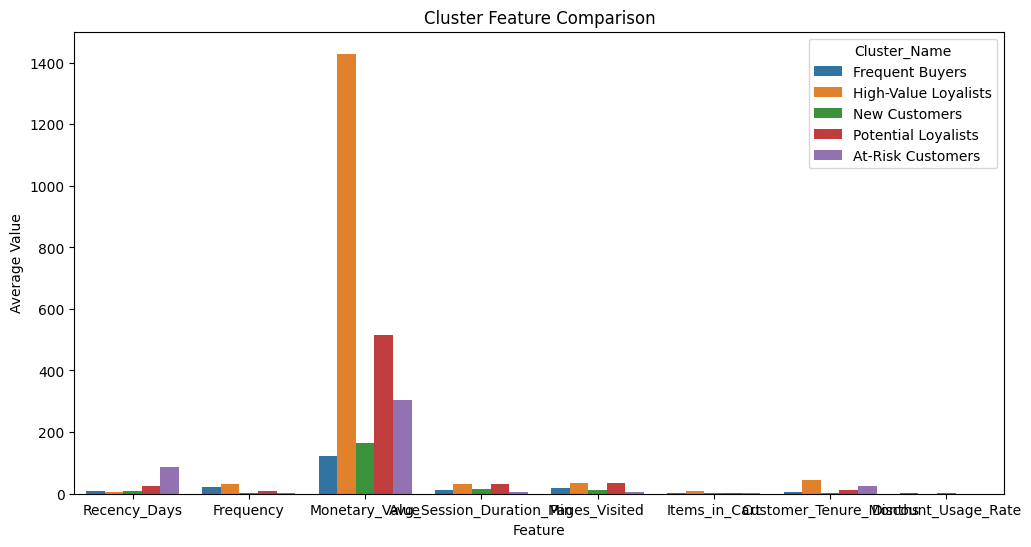

In [ ]:
plot_data = cluster_profile.reset_index().melt(
    id_vars=['Cluster', 'Cluster_Name', 'Size'],
    value_vars=num_features,
    var_name='Feature',
    value_name='Average'
)

plt.figure(figsize=(12,6))
sns.barplot(data=plot_data, x='Feature', y='Average', hue='Cluster_Name')
plt.title('Cluster Feature Comparison')
plt.ylabel('Average Value')
plt.show()

High-Value Loyalists - These are our top customers. They spend the most, buy frequently, and are highly engaged. They have also shopped recently, which makes them perfect candidates for VIP offers or loyalty rewards.

Frequent Buyers - These customers buy often but don't spend as much individually. They are consistent and reliable, so strategies like cross-selling or upselling could help increase their value.

New Customers - They have just started engaging with us. Their spending and frequency are low, so they need attention, welcome campaigns, guidance, or incentives could help turn them into loyal customers.

Potential Loyalists - Medium spenders who aren't buying as often recently. They have potential, but we need to engage them more to encourage repeat purchases.

At-Risk Customers - These customers haven't shopped in a while, and their activity is low. They need targeted win-back campaigns or special offers to bring them back before they churn

Customer Segment Strategies

High-Value Loyalists: Reward and retain top customers with VIP programs, personalized offers, and early access.

Frequent Buyers: Encourage upselling and cross-selling to increase their spending.

New Customers: Build trust and engagement through welcome campaigns, tutorials, and small incentives.

Potential Loyalists: Re-engage with reminders, personalized offers, and limited-time promotions.

At-Risk Customers: Prevent churn with win-back campaigns, special discounts, and targeted messaging.

Elbow Method Importance

Helps pick the right number of clusters (K) by showing where adding more clusters doesn't significantly reduce WCSS.

Prevents underfitting (too few clusters, losing meaningful patterns) and overfitting (too many clusters, capturing noise).

# ASSIGNMENT 2

Assignment 2: NLP Sentiment Analysis on Product Reviews
Objective: Build an NLP pipeline to preprocess product review text and classify sentiment using a Naive Bayes classifier.

Dataset: Assignment-Dataset/assignment2_product_reviews.csv (135 reviews)

Features: Review_Text (text), Sentiment (target: Positive/Negative)

Context: A company wants to automatically classify customer reviews as positive or negative to quickly identify product issues and customer satisfaction trends.

Instructions:

Data Loading & Exploration

Load the dataset and display basic info
Check the class distribution (Positive vs. Negative)
Display 5 sample reviews from each class
Text Preprocessing Pipeline Apply the following NLP preprocessing steps to all reviews:

Convert text to lowercase
Tokenize the text using word_tokenize()
Remove stop words using NLTK's English stop word list
Remove punctuation and special characters
Apply stemming using PorterStemmer OR lemmatization using WordNetLemmatizer
Display 3 example reviews showing the text before and after preprocessing
Feature Extraction using Bag-of-Words

Use CountVectorizer from sklearn to convert preprocessed text into numerical features
Display the shape of the resulting feature matrix
Show the top 20 most frequent words in the vocabulary
Train-Test Split

Split data into training (80%) and test (20%) sets with random_state=42
Build Naive Bayes Classifier

Train a MultinomialNB classifier on the training data
Predict on the test set
Evaluate using:
Confusion matrix
Accuracy score
Classification report (precision, recall, F1-score)
Feature Importance Analysis

Identify the top 10 words most associated with positive reviews
Identify the top 10 words most associated with negative reviews
Display these in a clear format
Test with Custom Reviews

Write 3 of your own product review sentences
Preprocess them using the same pipeline
Use the trained model to predict their sentiment
Discuss whether the predictions are accurate
Deliverables:

EDA visualizations and class distribution
Preprocessed text examples (before and after)
Confusion matrix and classification report
Top positive and negative indicator words
Custom review predictions with discussion

In [ ]:
#importing the necessary libraries
import nltk
import re
import string
from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import stopwords

# Download required NLTK resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('maxent_ne_chunker')
nltk.download('words')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('maxent_ne_chunker_tab')



[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package maxent_ne_chunker to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping chunkers/maxent_ne_chunker.zip.
[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Unzipping corpora/words.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading packag

True

In [ ]:
#importing the dataset
df = pd.read_csv('/content/drive/MyDrive/assignment2_product_reviews.csv')
df.head()

,Review_ID,Review_Text,Sentiment
0,1,Wasted my hard-earned money on this useless pr...,Negative
1,2,This is the gold standard for products in this...,Positive
2,3,The adhesive failed within hours. Product fell...,Negative
3,4,Terrific product with amazing features. The ba...,Positive
4,5,Premium quality at an affordable price. This p...,Positive


In [ ]:
# Dataset shape
df.shape

(135, 3)

In [ ]:
# data information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Review_ID    135 non-null    int64 
 1   Review_Text  135 non-null    object
 2   Sentiment    135 non-null    object
dtypes: int64(1), object(2)
memory usage: 3.3+ KB


In [ ]:
# Check missing values
df.isnull().sum()

,0
Review_ID,0
Review_Text,0
Sentiment,0


In [ ]:
# Checking for the unique values
print(df['Sentiment'].unique())

# Counting the text distribution
class_distribution = df['Sentiment'].value_counts()

print(class_distribution)

# Percentage distribution
print("\nPercentage Distribution:")
print(df['Sentiment'].value_counts(normalize=True) * 100)

['Negative' 'Positive']
Sentiment
Positive    70
Negative    65
Name: count, dtype: int64

Percentage Distribution:
Sentiment
Positive    51.851852
Negative    48.148148
Name: proportion, dtype: float64


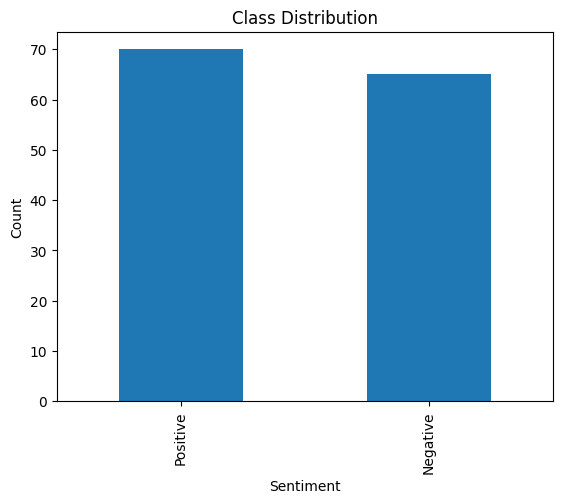

In [ ]:
#sentiments & class distribution visualization
df['Sentiment'].value_counts().plot(kind='bar')
plt.title("Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()

In [ ]:
# displaying 5 Positive Reviews and negative reviews
# 5 Positive Reviews
print(" Positive Reviews")
print(df[df['Sentiment'] == 'Positive']['Review_Text'].head(5))

# 5 Negative Reviews
print("\n Negative Reviews ")
print(df[df['Sentiment'] == 'Negative']['Review_Text'].head(5))

 Positive Reviews
1    This is the gold standard for products in this...
3    Terrific product with amazing features. The ba...
4    Premium quality at an affordable price. This p...
5    Happy to report that after six months of daily...
6    My family loves this product. It has become an...
Name: Review_Text, dtype: object

 Negative Reviews 
0    Wasted my hard-earned money on this useless pr...
2    The adhesive failed within hours. Product fell...
7    This product has a terrible chemical smell tha...
8    The latch mechanism broke immediately. This pr...
9    This product vibrates excessively during opera...
Name: Review_Text, dtype: object


The pipeline entails:
Lowercasing

Removing punctuation

Removing numbers

Tokenization

Stopword removal

Lemmatization

In [ ]:
#creating a function to perform the data pipeline creation
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):

    # 1. Lowercase
    text = text.lower()

    # 2. Remove numbers
    text = re.sub(r'\d+', '', text)

    # 3. Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # 4. Tokenization
    tokens = word_tokenize(text)

    # 5. Remove stopwords
    tokens = [word for word in tokens if word not in stop_words]

    # 6. Lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    return " ".join(tokens)

In [ ]:
#applying the function to the whole dataset
df['cleaned_review'] = df['Review_Text'].apply(preprocess_text)
df[['Review_Text', 'cleaned_review']].head()

,Review_Text,cleaned_review
0,Wasted my hard-earned money on this useless pr...,wasted hardearned money useless product make m...
1,This is the gold standard for products in this...,gold standard product category nothing else ev...
2,The adhesive failed within hours. Product fell...,adhesive failed within hour product fell apart...
3,Terrific product with amazing features. The ba...,terrific product amazing feature battery life ...
4,Premium quality at an affordable price. This p...,premium quality affordable price product steal...


In [ ]:
#converting the text to numerical features
from sklearn.feature_extraction.text import CountVectorizer

# Initialize CountVectorizer
vectorizer = CountVectorizer()

# Fit and transform the processed reviews
X = vectorizer.fit_transform(df["cleaned_review"])

# Convert to array (optional for viewing)
X_array = X.toarray()

print("Feature Matrix Shape:", X.shape)


Feature Matrix Shape: (135, 578)


In [ ]:
# Sum word counts across all documents
word_counts = np.sum(X_array, axis=0)

# Getting the  vocabulary
vocab = vectorizer.get_feature_names_out()

# Creating the  DataFrame
word_freq = pd.DataFrame({
    "word": vocab,
    "frequency": word_counts
})

# Sort by frequency descending
top_20 = word_freq.sort_values(by="frequency", ascending=False).head(20)

print(top_20)

            word  frequency
390      product         96
401      quality         26
535          use         18
567         work         10
397     purchase          9
510         time          8
366  performance          8
338      nothing          7
167         even          7
136       design          7
201      feature          7
175      exactly          6
238        great          6
95    completely          6
504     terrible          6
377         poor          6
387        price          6
116     customer          6
298         love          6
189    extremely          6


In [ ]:
#working on train and test splitting
from sklearn.model_selection import train_test_split
Y = df['Sentiment']

X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.20, random_state= 42)

print("Training Set Shape:", X_train.shape)
print("Testing Set Shape:", X_test.shape)


Training Set Shape: (108, 578)
Testing Set Shape: (27, 578)


In [ ]:
#training the naive bayes multinomial model
from sklearn.naive_bayes import MultinomialNB

#initializing the model
model = MultinomialNB()

#Training the model
model.fit(X_train, Y_train)

MultinomialNB()

In [ ]:
#making the predictions on the test set
Y_pred =model.predict(X_test)
print(Y_pred)

['Negative' 'Positive' 'Positive' 'Positive' 'Positive' 'Positive'
 'Negative' 'Negative' 'Negative' 'Negative' 'Positive' 'Positive'
 'Positive' 'Positive' 'Negative' 'Positive' 'Positive' 'Negative'
 'Positive' 'Positive' 'Positive' 'Positive' 'Negative' 'Negative'
 'Positive' 'Positive' 'Positive']


In [ ]:
#calculating the metrics
#confusion matrix
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(Y_test, Y_pred)
print("Confusion matrix:", cm)

Confusion matrix: [[ 4  6]
 [ 5 12]]


In [ ]:
#accuracy score
accuracy = accuracy_score(Y_test, Y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.5925925925925926


In [ ]:
#classification report
from sklearn.metrics import classification_report

print("classification report:")
print(classification_report(Y_test, Y_pred))

classification report:
              precision    recall  f1-score   support

    Negative       0.44      0.40      0.42        10
    Positive       0.67      0.71      0.69        17

    accuracy                           0.59        27
   macro avg       0.56      0.55      0.55        27
weighted avg       0.58      0.59      0.59        27



In [ ]:
#FEATURE IMPORTANCE ANALYSIS
feature_name = vectorizer.get_feature_names_out()

In [ ]:
# Difference between Positive and Negative
log_prob_diff = model.feature_log_prob_[1] - model.feature_log_prob_[0]

top_positive = np.argsort(log_prob_diff)[::-1][:10]
top_negative = np.argsort(log_prob_diff)[:10]

print("\nMost Positive Words:")
for idx in top_positive:
    print(feature_name[idx])

print("\nMost Negative Words:")
for idx in top_negative:
    print(feature_name[idx])


Most Positive Words:
great
daily
love
excellent
perfect
highly
recommend
happy
everyone
exactly

Most Negative Words:
poor
extremely
within
terrible
clearly
first
frustrating
failed
constantly
despite


In [ ]:
#creating new reviews
new_reviews = [
    "This product is absolutely amazing and works perfectly every day!",
    "Very disappointed. It stopped working after one week and feels cheap.",
    "The design is nice and the quality is decent for the price."
]

In [ ]:
#processing the new words
processed_new_reviews = [preprocess_text(review) for review in new_reviews]

print("Processed Reviews:")
for review in processed_new_reviews:
    print(review)

Processed Reviews:
product absolutely amazing work perfectly every day
disappointed stopped working one week feel cheap
design nice quality decent price


In [ ]:
#converting the numerical features
X_new = vectorizer.transform(processed_new_reviews)

In [ ]:
#predicting the new dataset
predn = model.predict(X_new)

for review, prediction in zip(new_reviews, predn):
  print("\nReview:", review)
  print("Predicted Sentiment:", prediction)


Review: This product is absolutely amazing and works perfectly every day!
Predicted Sentiment: Positive

Review: Very disappointed. It stopped working after one week and feels cheap.
Predicted Sentiment: Negative

Review: The design is nice and the quality is decent for the price.
Predicted Sentiment: Positive


**Discussion**

### model predictions analysis
1. Review: This product is absolutely amazing and works perfectly every day!
Predicted Sentiment: Positive (model predicted this correcly)

2. Review: Very disappointed. It stopped working after one week and feels cheap.
Predicted Sentiment: Negative (True)

3. Review: The design is nice and the quality is decent for the price.
Predicted Sentiment: Positive
this one is more neutral-positive. The model predicted Positive because of words like nice and quality, which makes sense, though its not a super strong sentiment either way.
the three predictions are all true only that for the last one its not a strong positive.


Assignment 3: Dimensionality Reduction — PCA vs. LDA Comparison
Objective: Compare Principal Component Analysis (PCA) and Linear Discriminant Analysis (LDA) on a wine classification dataset by reducing 13 features to 2 components and evaluating classification performance.

Dataset: Assignment-Dataset/assignment3_wine_dimensionality.csv (300 samples, 3 classes)

Features: Alcohol, Malic_Acid, Ash, Alcalinity_of_Ash, Magnesium, Total_Phenols, Flavanoids, Nonflavanoid_Phenols, Proanthocyanins, Color_Intensity, Hue, OD280_OD315, Proline

Target: Wine_Class (1, 2, or 3)

Context: A wine producer wants to classify wine varieties. With 13 chemical features, visualization and model training can be complex. Use dimensionality reduction to simplify the problem while maintaining classification accuracy.

Instructions:

Data Loading & Exploration

Load the dataset and display basic info
Check the class distribution of Wine_Class
Generate descriptive statistics for all 13 features
Check for missing values
Exploratory Data Analysis

Create box plots for key features grouped by Wine_Class
Generate a correlation heatmap for all 13 features
Identify which features show the most separation between classes
Data Preprocessing

Separate features (X) and target (y)
Split into training (80%) and test (20%) sets with random_state=0
Apply StandardScaler to both training and test sets
Apply PCA (Unsupervised)

Apply PCA with n_components=2
Record the explained variance ratio for each component
Transform both training and test sets
Visualize the 2D PCA projection, coloring points by Wine_Class
Apply LDA (Supervised)

Apply LDA with n_components=2
Record the explained variance ratio for each component
Transform both training and test sets
Visualize the 2D LDA projection, coloring points by Wine_Class
Classification on Reduced Data

For BOTH PCA-reduced and LDA-reduced data:
Train a Logistic Regression classifier (random_state=0)
Predict on the test set
Evaluate using confusion matrix and accuracy score
Comparison & Discussion

Create a comparison table: | Method | Component 1 Variance | Component 2 Variance | Total Variance Explained | Classification Accuracy |
Which method provides better class separation visually?
Which method yields higher classification accuracy and why?
Explain the fundamental difference between PCA and LDA (unsupervised vs. supervised)
When would you choose PCA over LDA and vice versa?
Deliverables:

Complete EDA with visualizations
PCA and LDA 2D scatter plot visualizations (side by side)
Confusion matrices for both methods
Comparison table with explained variance and accuracy
Written discussion on PCA vs. LDA differences and use cases


In [ ]:
#importing the dataset
dataset = pd.read_csv("/content/drive/MyDrive/assignment3_wine_dimensionality.csv")
dataset.head()

,Alcohol,Malic_Acid,Ash,Alcalinity_of_Ash,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280_OD315,Proline,Wine_Class
0,13.66,4.17,2.59,26.45,114.94,1.30,0.81,0.55,0.83,6.99,0.75,1.69,358.23,3
1,13.13,3.62,2.10,25.42,103.23,1.20,0.85,0.58,1.01,7.34,0.68,1.82,294.31,3
2,13.38,1.87,2.40,20.41,116.05,1.91,2.32,0.29,0.95,5.78,0.93,2.23,613.72,2
3,13.14,2.59,2.15,17.05,109.17,2.91,2.57,0.32,2.38,4.95,1.05,3.37,1495.27,1
4,12.51,4.06,2.04,20.15,68.38,1.71,1.18,0.36,0.99,8.86,0.92,2.06,147.98,3


In [ ]:
#EDA PROCESS
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               300 non-null    float64
 1   Malic_Acid            300 non-null    float64
 2   Ash                   300 non-null    float64
 3   Alcalinity_of_Ash     300 non-null    float64
 4   Magnesium             300 non-null    float64
 5   Total_Phenols         300 non-null    float64
 6   Flavanoids            300 non-null    float64
 7   Nonflavanoid_Phenols  300 non-null    float64
 8   Proanthocyanins       300 non-null    float64
 9   Color_Intensity       300 non-null    float64
 10  Hue                   300 non-null    float64
 11  OD280_OD315           300 non-null    float64
 12  Proline               300 non-null    float64
 13  Wine_Class            300 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 32.9 KB


In [ ]:
#data statistical analysis
dataset.describe()

,Alcohol,Malic_Acid,Ash,Alcalinity_of_Ash,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280_OD315,Proline,Wine_Class
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,13.003567,2.646867,2.268000,19.694367,106.527467,2.152767,2.010200,0.388100,1.426467,5.795100,0.890567,2.675500,725.119700,2.000000
std,0.659890,0.773274,0.297378,3.406138,19.870249,0.630300,0.925442,0.115987,0.468059,1.523072,0.203309,0.616357,369.148257,0.817861
min,10.790000,1.050000,1.450000,12.050000,50.990000,0.480000,0.420000,0.150000,0.250000,1.670000,0.390000,1.210000,89.260000,1.000000
25%,12.560000,2.105000,2.097500,17.190000,92.702500,1.675000,1.210000,0.300000,1.037500,4.897500,0.740000,2.140000,437.460000,1.000000
50%,13.060000,2.525000,2.260000,19.430000,105.485000,2.230000,1.995000,0.350000,1.445000,5.630000,0.890000,2.740000,599.625000,2.000000
75%,13.450000,3.132500,2.440000,21.982500,116.897500,2.610000,2.852500,0.460000,1.780000,6.805000,1.040000,3.180000,1036.175000,3.000000
max,14.950000,4.640000,3.160000,29.890000,175.100000,3.790000,3.990000,0.700000,2.500000,10.490000,1.440000,3.810000,1680.420000,3.000000


In [ ]:
#checking for null values
dataset.isna().sum()

,0
Alcohol,0
Malic_Acid,0
Ash,0
Alcalinity_of_Ash,0
Magnesium,0
Total_Phenols,0
Flavanoids,0
Nonflavanoid_Phenols,0
Proanthocyanins,0
Color_Intensity,0


/tmp/ipython-input-1677001776.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = 'Wine_Class', y = feature, data =dataset, palette = 'Set2')
/tmp/ipython-input-1677001776.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = 'Wine_Class', y = feature, data =dataset, palette = 'Set2')
/tmp/ipython-input-1677001776.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = 'Wine_Class', y = feature, data =dataset, palette = 'Set2')
/tmp/ipython-input-1677001776.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated 

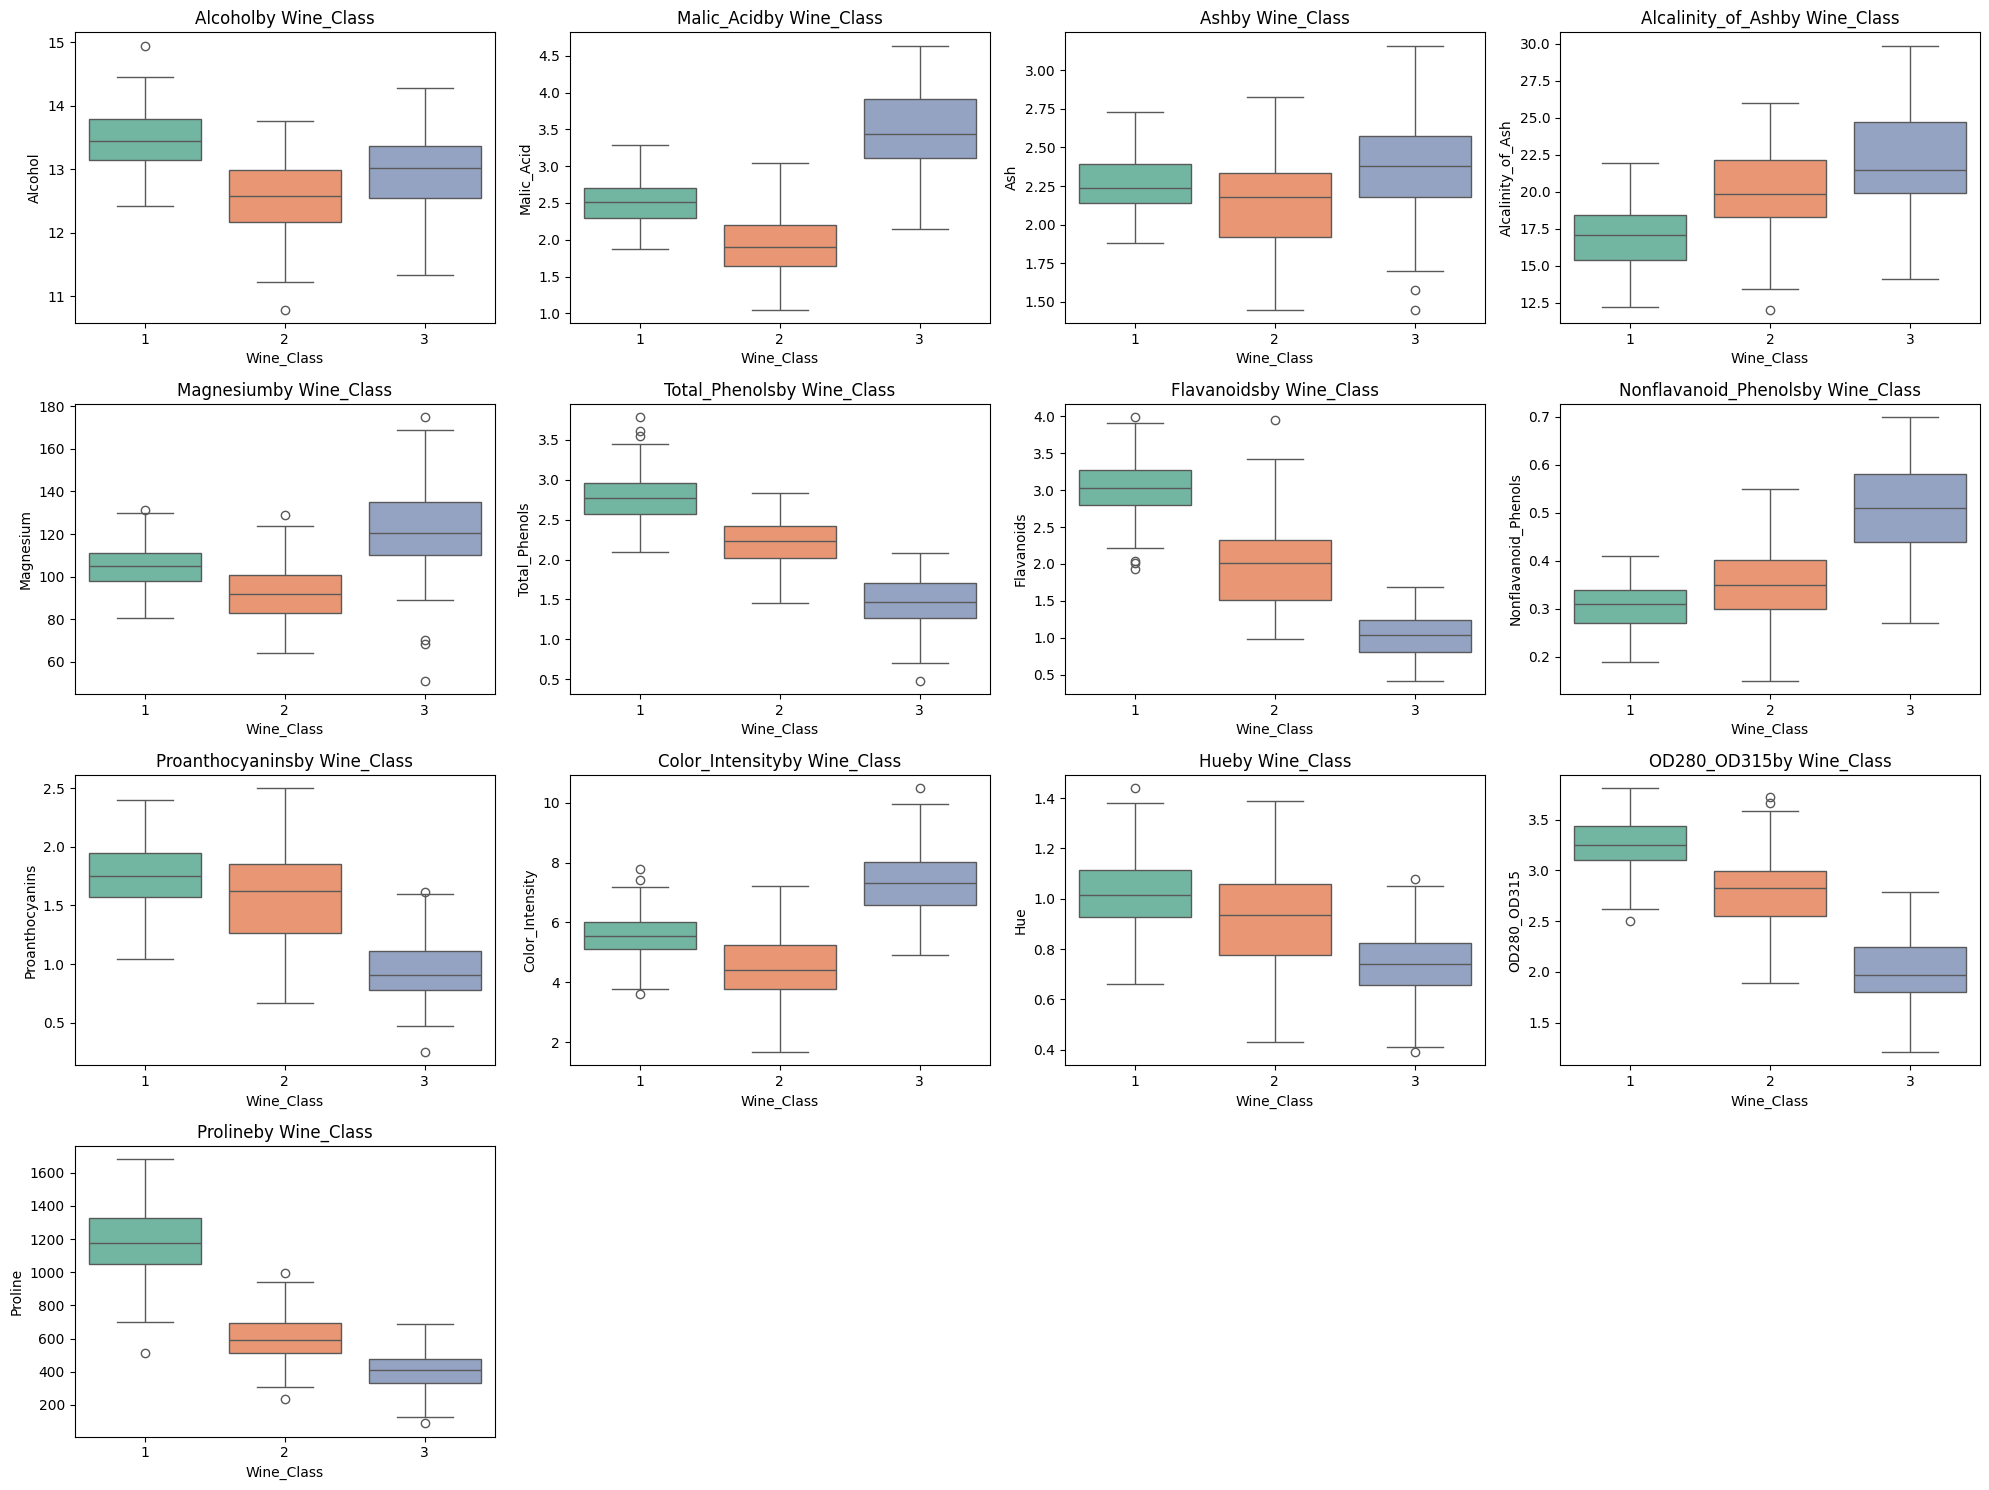

In [ ]:
#creating the box plot
features = dataset.columns[:-1]

plt.figure(figsize=(20,15))
for i, feature in enumerate(features, 1):
  plt.subplot(4, 4, i)
  sns.boxplot(x = 'Wine_Class', y = feature, data =dataset, palette = 'Set2')
  plt.title(f"{feature}by Wine_Class")
  plt.tight_layout()

plt.show()

In [ ]:
#separating and x and y
x=dataset.drop('Wine_Class', axis =1)
y=dataset['Wine_Class']

In [ ]:
#data splitting
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.20, random_state=0)

In [ ]:
#standard scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data and transform both training and test
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Scaled Training shape:", x_train_scaled.shape)
print("Scaled Test shape:", x_test_scaled.shape)

Scaled Training shape: (240, 13)
Scaled Test shape: (60, 13)


In [ ]:
from sklearn.decomposition import PCA
#applying the PCA with 2 components
pca = PCA(n_components=2)

x_train_pca = pca.fit_transform(x_train_scaled)
x_test_pca = pca.transform(x_test_scaled)
#variance ratio
explained_variance = pca.explained_variance_ratio_

print("Explained variance ratio:", explained_variance)
print("Total variance explained:", explained_variance.sum())

Explained variance ratio: [0.47057984 0.13319638]
Total variance explained: 0.6037762179711273


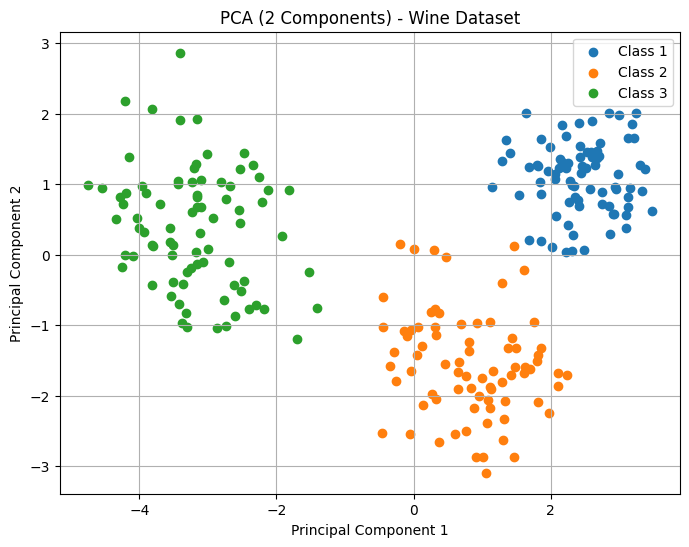

In [ ]:
#visualizing 2d pca projection
plt.figure(figsize=(8,6))

for class_label in np.unique(y_train):
    plt.scatter(
        x_train_pca[y_train == class_label, 0],
        x_train_pca[y_train == class_label, 1],
        label=f"Class {class_label}"
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA (2 Components) - Wine Dataset")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

# For 3 classes, max components = (n_classes - 1) = 2
lda = LDA(n_components=2)

x_train_lda = lda.fit_transform(x_train_scaled, y_train)
x_test_lda = lda.transform(x_test_scaled)

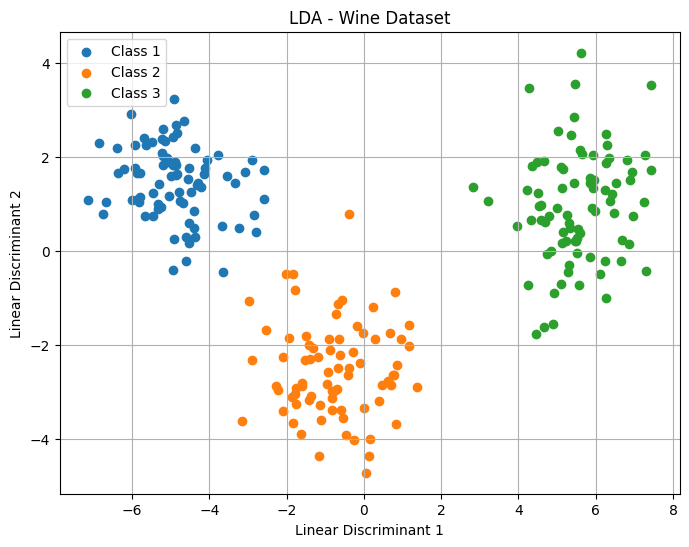

In [ ]:
#visualizing the LDA projection
plt.figure(figsize=(8,6))
for class_label in np.unique(y_train):
  plt.scatter(
      x_train_lda[y_train == class_label, 0],
      x_train_lda[y_train == class_label, 1],
      label=f"Class {class_label}"


  )
plt.xlabel("Linear Discriminant 1")
plt.ylabel("Linear Discriminant 2")
plt.title("LDA - Wine Dataset")
plt.legend()
plt.grid(True)
plt.show()

**Dimensionality Reduction Summary (PCA vs LDA)**

After applying both PCA and LDA to the Wine dataset, I observed a clear difference in how the two methods behaved.

PCA reduced the dataset to two components while preserving the maximum overall variance. The visualization showed decent clustering, but there was still some overlap between classes. This makes sense because PCA does not consider class labels, it only focuses on capturing the directions where the data varies the most. So while it simplifies the dataset effectively, it does not intentionally separate the wine classes.

LDA, on the other hand, produced much cleaner class separation. The clusters were more distinct and clearly divided. This is because LDA is supervised, it uses the Wine_Class labels during transformation and specifically maximizes the distance between classes while minimizing variation within each class.

**When to choose PCA**
1.when I do not have labels (unsupervised learning)

2.My goal is dimensionality reduction or visualization.

3.I want to remove multicollinearity and noise.

4.I need to compress features before applying another model.

**When to Choose LDA**

1.I am solving a classification problem.

2.Labels are available.

3.My main goal is maximizing class separation.

4.I want improved predictive performance.

**Conclusion**

While PCA successfully reduced dimensionality and preserved variance, LDA provided stronger class separation because it incorporated label information. Therefore, for classification problems like wine prediction, LDA is the better choice.
